# Qwen3.5-27B Post-LoRA L50 Frozen Rank-4 Blind-v3 Replication

上一轮在完全 held-out 的 strict weight-conflict scenes 上发现：由 development 数据冻结的 L50 `joint_svd_rank4` 子空间，在 Native→LoRA 与 LoRA→Native 两个方向分别恢复完整 L50 state patch 约 91% 和 90% 的 correct-margin 效应。

[实验设置与运行说明](../../../docs/experiment_notes/07_appendix_lora_training/4779572ed6f053db.md)


In [1]:
# Run once. Every later code cell reports progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 14 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 14 tracked cells.


## 1. Freeze first, then create a new test

The saved adapter and the development-learned rank-4 basis are immutable inputs.


In [2]:
%%cell_progress 1/14 Mount Drive and select a complete VisualTorque project
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Auditing candidate project roots')
from pathlib import Path
import shutil

PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
REQUIRED_TOOLKIT_PATHS = (
    'pyproject.toml',
    'src/visual_torque_toolkit/__init__.py',
    'src/visual_torque_toolkit/contracts.py',
    'src/visual_torque_toolkit/classify.py',
    'src/visual_torque_toolkit/dataset.py',
    'src/visual_torque_toolkit/edits.py',
    'src/visual_torque_toolkit/generate.py',
    'src/visual_torque_toolkit/prompts.py',
    'src/visual_torque_toolkit/render.py',
    'src/visual_torque_toolkit/splits.py',
    'src/visual_torque_toolkit/world.py',
    'src/visual_torque_toolkit/behavior/__init__.py',
    'src/visual_torque_toolkit/behavior/adapter.py',
    'src/visual_torque_toolkit/behavior/data.py',
    'src/visual_torque_toolkit/behavior/schema.py',
)

def missing_toolkit_paths(project_root):
    toolkit_root = project_root / 'toolkit'
    return [
        relative for relative in REQUIRED_TOOLKIT_PATHS
        if not (toolkit_root / relative).is_file()
    ]

candidate_audit = {
    str(candidate): missing_toolkit_paths(candidate)
    for candidate in PROJECT_CANDIDATES
}
complete_candidates = [
    candidate for candidate in PROJECT_CANDIDATES
    if not candidate_audit[str(candidate)]
]
assert complete_candidates, (
    'No complete VisualTorque toolkit was found. '
    f'Missing-file audit: {candidate_audit}'
)
PROJECT_ROOT = complete_candidates[0]

cell_stage('Copying immutable toolkit source to local SSD')
DRIVE_TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
TOOLKIT_ROOT = Path('/content/visualtorque_toolkit_runtime')
if TOOLKIT_ROOT.exists():
    shutil.rmtree(TOOLKIT_ROOT)
shutil.copytree(DRIVE_TOOLKIT_ROOT, TOOLKIT_ROOT)
print('Project:', PROJECT_ROOT)
print('Toolkit runtime:', TOOLKIT_ROOT)


Mount Drive and select a complete VisualTorque project:   0%|          | 0/14 [00:00<?, ?cell/s]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/VisualTorque
Toolkit runtime: /content/visualtorque_toolkit_runtime


In [3]:
%%cell_progress 2/14 Install and verify the frozen inference environment
import importlib
import importlib.metadata
import json
import os
import subprocess
import sys

cell_stage('Configuring caches before importing Torch')
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
os.environ.setdefault('HF_HOME', '/content/hf_cache')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

cell_stage('Removing incompatible optional Torch packages')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio', 'torchao'],
    check=False,
)
importlib.invalidate_caches()

cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    '--upgrade-strategy', 'only-if-needed',
    'transformers==5.14.0', 'peft==0.20.0', 'accelerate>=1.10',
    'sentencepiece', 'protobuf', 'huggingface_hub>=0.34',
    'safetensors', 'tqdm>=4.66', 'scikit-learn>=1.5',
    'scipy>=1.13', 'pandas>=2.2', 'matplotlib>=3.8',
    'joblib>=1.4', 'pillow>=10.4',
])

cell_stage('Importing the immutable toolkit copy')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if module_name == 'visual_torque_toolkit' or module_name.startswith('visual_torque_toolkit.'):
        del sys.modules[module_name]
importlib.invalidate_caches()

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import visual_torque_toolkit
from IPython.display import display
from peft import PeftModel
from scipy.stats import binomtest
from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter
from visual_torque_toolkit.generate import (
    GenerationConfig, generate_multi_stack_scenes,
)
from visual_torque_toolkit.prompts import QuestionKind, generate_questions
from visual_torque_toolkit.render import RenderStyle, render_scene

# Defensive Qwen3.5 compatibility patch for exact candidate scoring.
def append_text_prefix_aligned(self, inputs, prefix):
    if not prefix:
        return inputs
    batch_size = inputs['input_ids'].shape[0]
    prefix_tensor = torch.tensor(
        prefix,
        dtype=inputs['input_ids'].dtype,
        device=inputs['input_ids'].device,
    ).unsqueeze(0).expand(batch_size, -1)
    inputs['input_ids'] = torch.cat((inputs['input_ids'], prefix_tensor), dim=1)
    attention_extension = torch.ones(
        (batch_size, len(prefix)),
        dtype=inputs['attention_mask'].dtype,
        device=inputs['attention_mask'].device,
    )
    inputs['attention_mask'] = torch.cat(
        (inputs['attention_mask'], attention_extension), dim=1
    )
    for key in ('token_type_ids', 'mm_token_type_ids'):
        if key not in inputs:
            continue
        extension = torch.zeros(
            (batch_size, len(prefix)),
            dtype=inputs[key].dtype,
            device=inputs[key].device,
        )
        inputs[key] = torch.cat((inputs[key], extension), dim=1)
    inputs.pop('position_ids', None)
    return inputs

HuggingFaceMultimodalAdapter._append_text_prefix = append_text_prefix_aligned
torch.backends.cuda.matmul.allow_tf32 = True
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents
try:
    torchao_version = importlib.metadata.version('torchao')
except importlib.metadata.PackageNotFoundError:
    torchao_version = None
assert torchao_version is None
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('transformers:', importlib.metadata.version('transformers'))
print('peft:', importlib.metadata.version('peft'))
print('Toolkit:', toolkit_path)


Install and verify the frozen inference environment:   7%|7         | 1/14 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
transformers: 5.14.0
peft: 0.20.0
Toolkit: /content/visualtorque_toolkit_runtime/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/14 Freeze the prior rank-4 result and the blind-v3 protocol
cell_stage('Checking GPU and immutable prerequisites')
import hashlib
from collections import Counter, defaultdict
from contextlib import contextmanager
from datetime import datetime, timezone
from zipfile import ZipFile

assert torch.cuda.is_available(), 'Select a GPU runtime.'
GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY_GIB = torch.cuda.get_device_properties(0).total_memory / 2**30
assert GPU_MEMORY_GIB >= 88, (GPU_NAME, GPU_MEMORY_GIB)

MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
EXPECTED_LAYER_COUNT = 64
L50 = 50
SEED = 20260911
CANDIDATE_COUNT = 40000
PRIMARY_CELLS = (('left', 'right'), ('right', 'left'))
PRIMARY_SCENES_PER_CELL = 12
SECONDARY_SCENES_PER_CELL = 4
PATCH_BATCH_SIZE = 4
BOOTSTRAP_REPLICATES = 10000
SIGN_FLIP_REPLICATES = 10000
RANDOM_SUBSPACE_COUNT = 99
NONINFERIORITY_FRACTION = 0.80
ALPHA_LEVEL = 0.05
RUN_VERSION = 'v1'

TRAIN_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_bf16_lora_weight_shortcut_v1'
ADAPTER_DIR = TRAIN_ROOT / 'adapter_final'
ADAPTER_MANIFEST_PATH = TRAIN_ROOT / 'ADAPTER_MANIFEST.json'
BLIND_V1_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_postlora_blind_causal_validation_v1'
BLIND_V1_DATASET_DIR = BLIND_V1_ROOT / 'blind_dataset'
DECOMP_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_postlora_l50_causal_subspace_decomposition_v1'
DECOMP_COMPLETE_PATH = DECOMP_ROOT / 'RUN_COMPLETE.json'
DECOMP_DECISION_PATH = DECOMP_ROOT / 'analysis' / 'l50_causal_subspace_decision.json'
DECOMP_SUBSPACE_PATH = DECOMP_ROOT / 'development_frozen_subspaces.pt'
DECOMP_SELECTION_PATH = DECOMP_ROOT / 'FROZEN_SUBSPACE_SELECTION.json'
BLIND_V2_DATASET_DIR = DECOMP_ROOT / 'blind_v2_dataset'

for required in (
    ADAPTER_DIR / 'adapter_config.json', ADAPTER_MANIFEST_PATH,
    BLIND_V1_ROOT / 'RUN_COMPLETE.json',
    BLIND_V1_DATASET_DIR / 'scenes.jsonl',
    DECOMP_COMPLETE_PATH, DECOMP_DECISION_PATH,
    DECOMP_SUBSPACE_PATH, DECOMP_SELECTION_PATH,
    BLIND_V2_DATASET_DIR / 'scenes.jsonl',
):
    assert required.is_file(), required

def json_default(value):
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.generic):
        return value.item()
    if torch.is_tensor(value) and value.numel() == 1:
        return value.item()
    raise TypeError(f'Cannot serialize {type(value).__name__}')

def write_json_atomic(file_path, value):
    file_path = Path(file_path)
    temporary = file_path.with_suffix(file_path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(
            value, indent=2, ensure_ascii=False, sort_keys=True,
            default=json_default,
        ) + '\n',
        encoding='utf-8',
    )
    temporary.replace(file_path)

def write_jsonl_atomic(file_path, rows):
    file_path = Path(file_path)
    temporary = file_path.with_suffix(file_path.suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(
                row, ensure_ascii=False, sort_keys=True,
                default=json_default,
            ) + '\n')
    temporary.replace(file_path)

def read_jsonl(file_path):
    with Path(file_path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def sha256_file(file_path):
    digest = hashlib.sha256()
    with Path(file_path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value!r}'.encode('utf-8')).hexdigest()

adapter_manifest = json.loads(ADAPTER_MANIFEST_PATH.read_text(encoding='utf-8'))
selection_payload = json.loads(DECOMP_SELECTION_PATH.read_text(encoding='utf-8'))
prior_decision = json.loads(DECOMP_DECISION_PATH.read_text(encoding='utf-8'))
assert adapter_manifest['base_model_id'] == MODEL_ID
assert adapter_manifest['base_model_revision'] == MODEL_REVISION
selected = selection_payload['selected_candidate']
assert selection_payload['selection_status'] == 'qualified_minimum_rank'
assert selected['component_name'] == 'joint_svd_rank4', selected
assert selected['component_family'] == 'joint_svd', selected
assert int(selected['component_rank']) == 4, selected
prior_primary_gates = {
    key: value for key, value in prior_decision['gates'].items()
    if key != 'low_rank_causal_subspace_confirmed'
}
failed_prior_gates = sorted(
    key for key, value in prior_primary_gates.items() if not value
)
assert failed_prior_gates == [
    'selected_efficiency_beats_random_necessity'
], failed_prior_gates

OUTPUT_ROOT = (
    PROJECT_ROOT / 'results'
    / f'qwen27b_postlora_l50_frozen_rank4_blindv3_{RUN_VERSION}'
)
BLIND_V3_DATASET_DIR = OUTPUT_ROOT / 'blind_v3_dataset'
CLEAN_DIR = OUTPUT_ROOT / 'clean_states'
PATCH_DIR = OUTPUT_ROOT / 'patches'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for directory in (
    OUTPUT_ROOT, BLIND_V3_DATASET_DIR, CLEAN_DIR,
    PATCH_DIR, ANALYSIS_DIR, FIGURE_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

print('GPU:', GPU_NAME, '| memory GiB:', round(GPU_MEMORY_GIB, 1))
print('Frozen layer/rank:', L50, int(selected['component_rank']))
print('Prior unresolved gate:', failed_prior_gates[0])
print('Output:', OUTPUT_ROOT)


Freeze the prior rank-4 result and the blind-v3 protocol:  14%|#4        | 2/14 [00:00<?, ?cell/s]

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition | memory GiB: 95.0
Frozen layer/rank: 50 4
Prior unresolved gate: selected_efficiency_beats_random_necessity
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_frozen_rank4_blindv3_v1


In [5]:
%%cell_progress 4/14 Exclude every previously used geometry and lock the protocol
cell_stage('Locating Dataset v1')
REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
SOURCE_DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
DRIVE_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(dataset_path):
    return dataset_path.is_dir() and all(
        (dataset_path / filename).is_file()
        for filename in REQUIRED_DATASET_FILES
    )

if not dataset_complete(SOURCE_DATASET_DIR):
    SOURCE_DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            extraction_root = SOURCE_DATASET_DIR.resolve()
            for member in tqdm(
                [item for item in bundle.infolist() if not item.is_dir()],
                desc='Extracting Dataset v1', unit='file',
            ):
                target = (SOURCE_DATASET_DIR / member.filename).resolve()
                if extraction_root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, SOURCE_DATASET_DIR)
        if not dataset_complete(SOURCE_DATASET_DIR):
            nested = [
                item for item in SOURCE_DATASET_DIR.iterdir()
                if dataset_complete(item)
            ]
            assert len(nested) == 1, nested
            SOURCE_DATASET_DIR = nested[0]
    elif dataset_complete(DRIVE_DATASET_DIR):
        shutil.copytree(DRIVE_DATASET_DIR, SOURCE_DATASET_DIR, dirs_exist_ok=True)
    else:
        raise FileNotFoundError(
            'Place dataset_v1.zip or a complete dataset_v1 directory '
            'under VisualTorque/data on Drive.'
        )
assert dataset_complete(SOURCE_DATASET_DIR)

source_scenes = read_jsonl(SOURCE_DATASET_DIR / 'scenes.jsonl')
blind_v1_scenes = read_jsonl(BLIND_V1_DATASET_DIR / 'scenes.jsonl')
blind_v2_scenes = read_jsonl(BLIND_V2_DATASET_DIR / 'scenes.jsonl')

protocol_identity = {
    'schema_version': 'qwen27b-postlora-l50-frozen-rank4-blindv3-1.0',
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'adapter_manifest_sha256': sha256_file(ADAPTER_MANIFEST_PATH),
    'decomposition_complete_sha256': sha256_file(DECOMP_COMPLETE_PATH),
    'decomposition_decision_sha256': sha256_file(DECOMP_DECISION_PATH),
    'decomposition_subspaces_sha256': sha256_file(DECOMP_SUBSPACE_PATH),
    'decomposition_selection_sha256': sha256_file(DECOMP_SELECTION_PATH),
    'source_dataset_hashes': {
        name: sha256_file(SOURCE_DATASET_DIR / name)
        for name in sorted(REQUIRED_DATASET_FILES)
    },
    'blind_v1_scenes_sha256': sha256_file(BLIND_V1_DATASET_DIR / 'scenes.jsonl'),
    'blind_v2_scenes_sha256': sha256_file(BLIND_V2_DATASET_DIR / 'scenes.jsonl'),
    'layer_index': L50,
    'selected_name': selected['component_name'],
    'selected_rank': int(selected['component_rank']),
    'seed': SEED,
    'candidate_count': CANDIDATE_COUNT,
    'primary_cells': [list(cell) for cell in PRIMARY_CELLS],
    'primary_scenes_per_cell': PRIMARY_SCENES_PER_CELL,
    'secondary_scenes_per_cell': SECONDARY_SCENES_PER_CELL,
    'random_subspace_count': RANDOM_SUBSPACE_COUNT,
    'noninferiority_fraction': NONINFERIORITY_FRACTION,
    'primary_unit': 'physical scene after A/B/C permutation averaging',
    'primary_scope': 'strict nonbalanced weight-outcome conflict only',
    'gate_rule': (
        'On new primary conflict scenes: LoRA accuracy improvement has positive '
        '95% scene-bootstrap CI; full and frozen-rank4 sufficiency/necessity '
        'have positive CIs; frozen rank4 is at least 80% non-inferior to full '
        'in both directions; raw and effect-per-projected-norm empirical p are '
        '<=0.05 against 99 frozen rank-matched controls in both directions; '
        'and all A/B/C selected-effect strata have positive CIs.'
    ),
    'secondary_scope_rule': (
        'All non-primary 3x3 weight/outcome cells are diagnostic only and '
        'cannot rescue or invalidate the primary gate.'
    ),
    'ordering_rule': (
        'Protocol, dataset, manifest, selected basis, and random bases are '
        'frozen before any blind-v3 model forward.'
    ),
}
PROTOCOL_LOCK_PATH = OUTPUT_ROOT / 'frozen_protocol.json'
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Existing protocol differs. Increment RUN_VERSION.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Dataset v1 excluded:', len(source_scenes))
print('Blind v1 excluded:', len(blind_v1_scenes))
print('Blind v2 excluded:', len(blind_v2_scenes))
print('Protocol locked before blind-v3 inference:', PROTOCOL_LOCK_PATH)


Exclude every previously used geometry and lock the protocol:  21%|##1       | 3/14 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset v1 excluded: 2100
Blind v1 excluded: 216
Blind v2 excluded: 48
Protocol locked before blind-v3 inference: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_frozen_rank4_blindv3_v1/frozen_protocol.json


In [6]:
%%cell_progress 5/14 Generate and lock the broader blind-v3 dataset
cell_stage('Enumerating new multi-stack candidates')
ALL_CELLS = tuple(
    (weight_cue, outcome)
    for weight_cue in ('left', 'balanced', 'right')
    for outcome in ('left', 'balanced', 'right')
)

def object_signature(scene):
    left = tuple(sorted(
        (int(stack.distance), int(stack.units))
        for stack in scene.stacks if stack.side.value == 'left'
    ))
    right = tuple(sorted(
        (int(stack.distance), int(stack.units))
        for stack in scene.stacks if stack.side.value == 'right'
    ))
    return left, right

def record_signature(scene):
    left = tuple(sorted(
        (int(stack['distance']), int(stack['units']))
        for stack in scene['stacks'] if stack['side'] == 'left'
    ))
    right = tuple(sorted(
        (int(stack['distance']), int(stack['units']))
        for stack in scene['stacks'] if stack['side'] == 'right'
    ))
    return left, right

def weight_cue_object(scene):
    if scene.left_units > scene.right_units:
        return 'left'
    if scene.left_units < scene.right_units:
        return 'right'
    return 'balanced'

def regime_for(weight_cue, outcome):
    if weight_cue == outcome:
        return 'agreement'
    if (weight_cue, outcome) in PRIMARY_CELLS:
        return 'strict_conflict'
    return 'one_axis_balanced'

excluded_records = (*source_scenes, *blind_v1_scenes, *blind_v2_scenes)
excluded_signatures = {record_signature(scene) for scene in excluded_records}
candidate_config = GenerationConfig(
    max_units=5, max_distance=6, multi_max_units=4,
    multi_scene_count=CANDIDATE_COUNT, seed=SEED,
)
candidates = generate_multi_stack_scenes(candidate_config)
pools = defaultdict(list)
for scene in candidates:
    signature = object_signature(scene)
    mirror = (signature[1], signature[0])
    if signature in excluded_signatures or mirror in excluded_signatures:
        continue
    key = (weight_cue_object(scene), scene.outcome.value)
    if key in ALL_CELLS:
        pools[key].append(scene)

required_per_cell = {
    cell: (
        PRIMARY_SCENES_PER_CELL
        if cell in PRIMARY_CELLS else SECONDARY_SCENES_PER_CELL
    ) for cell in ALL_CELLS
}
for cell in ALL_CELLS:
    pools[cell].sort(key=lambda scene: stable_key(('pool', scene.scene_id)))
    assert len(pools[cell]) >= required_per_cell[cell], (cell, len(pools[cell]))

cell_stage('Selecting mirror-disjoint scenes with two unseen styles')
selected_scenes = []
selection_rows = []
selected_signatures = set()
style_names = ('ochre_shift', 'teal_shift')
for cell in ALL_CELLS:
    chosen = []
    for scene in pools[cell]:
        signature = object_signature(scene)
        mirror = (signature[1], signature[0])
        if signature in selected_signatures or mirror in selected_signatures:
            continue
        chosen.append(scene)
        selected_signatures.add(signature)
        if len(chosen) == required_per_cell[cell]:
            break
    assert len(chosen) == required_per_cell[cell], (cell, len(chosen))
    for cell_index, scene in enumerate(chosen):
        style = style_names[cell_index % 2]
        selection_rows.append({
            'scene_id': scene.scene_id,
            'weight_cue': cell[0],
            'outcome': cell[1],
            'regime': regime_for(*cell),
            'primary': cell in PRIMARY_CELLS,
            'style': style,
            'net_torque': int(scene.net_torque),
            'abs_net_torque': abs(int(scene.net_torque)),
            'signature': object_signature(scene),
        })
        selected_scenes.append(scene)

assert len(selected_scenes) == 52
assert sum(row['primary'] for row in selection_rows) == 24
assert not selected_signatures & excluded_signatures
assert not {(right, left) for left, right in selected_signatures} & excluded_signatures

STYLES = {
    'ochre_shift': RenderStyle(
        width=960, height=480, ticks_per_side=6, beam_y=305,
        block_size=28, block_gap=3,
        background=(249, 246, 238), ink=(48, 47, 43),
        block_fill=(193, 122, 34),
    ),
    'teal_shift': RenderStyle(
        width=1088, height=544, ticks_per_side=6, beam_y=345,
        block_size=31, block_gap=3,
        background=(239, 247, 246), ink=(29, 52, 58),
        block_fill=(30, 137, 145),
    ),
}
selection_by_scene = {row['scene_id']: row for row in selection_rows}
scene_records = []
question_records = []
for scene in tqdm(selected_scenes, desc='Rendering blind-v3 images', unit='image'):
    selection = selection_by_scene[scene.scene_id]
    relative_image = Path('images') / selection['style'] / f'{scene.scene_id}.png'
    destination = BLIND_V3_DATASET_DIR / relative_image
    if not destination.is_file():
        render_scene(scene, destination, STYLES[selection['style']])
    record = scene.to_record()
    record['split'] = 'blind_v3_confirmatory'
    record['image_path'] = relative_image.as_posix()
    record['metadata'] = {
        **record.get('metadata', {}),
        'family': 'multi_stack',
        'blind_style': selection['style'],
        'blind_seed': str(SEED),
        'blind_regime': selection['regime'],
        'primary': str(selection['primary']).lower(),
    }
    scene_records.append(record)
    for question in generate_questions(scene):
        if question.kind is QuestionKind.OUTCOME:
            question_records.append(
                question.to_record(split='blind_v3_confirmatory')
            )

assert len(scene_records) == 52
assert len(question_records) == 52 * 6
write_jsonl_atomic(BLIND_V3_DATASET_DIR / 'scenes.jsonl', scene_records)
write_jsonl_atomic(BLIND_V3_DATASET_DIR / 'questions.jsonl', question_records)
write_jsonl_atomic(BLIND_V3_DATASET_DIR / 'counterfactual_pairs.jsonl', [])
write_json_atomic(BLIND_V3_DATASET_DIR / 'dataset_config.json', {
    'schema_version': 'visualtorque-blind-v3-frozen-rank4-1.0',
    'candidate_generation': candidate_config.to_record(),
    'excludes_dataset_v1_blind_v1_blind_v2_and_mirrors': True,
    'styles': {
        name: {
            key: getattr(style, key)
            for key in (
                'width', 'height', 'ticks_per_side', 'beam_y',
                'block_size', 'block_gap', 'background', 'ink', 'block_fill',
            )
        } for name, style in STYLES.items()
    },
})
write_json_atomic(BLIND_V3_DATASET_DIR / 'splits.json', {
    'blind_v3_confirmatory': sorted(row['scene_id'] for row in selection_rows)
})
write_json_atomic(BLIND_V3_DATASET_DIR / 'statistics.json', {
    'scene_count': len(scene_records),
    'question_count': len(question_records),
    'primary_scene_count': sum(row['primary'] for row in selection_rows),
    'cell_counts': {
        '|'.join(key): int(value)
        for key, value in Counter(
            (row['weight_cue'], row['outcome']) for row in selection_rows
        ).items()
    },
})
write_json_atomic(BLIND_V3_DATASET_DIR / 'image_hashes.json', {
    row['scene_id']: sha256_file(
        BLIND_V3_DATASET_DIR / next(
            scene['image_path'] for scene in scene_records
            if scene['scene_id'] == row['scene_id']
        )
    ) for row in selection_rows
})
write_jsonl_atomic(OUTPUT_ROOT / 'blind_v3_scene_manifest.jsonl', selection_rows)

dataset_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'dataset_hashes': {
        name: sha256_file(BLIND_V3_DATASET_DIR / name)
        for name in sorted(REQUIRED_DATASET_FILES)
    },
    'image_hashes_sha256': sha256_file(BLIND_V3_DATASET_DIR / 'image_hashes.json'),
    'scene_manifest_sha256': sha256_file(OUTPUT_ROOT / 'blind_v3_scene_manifest.jsonl'),
    'prior_geometry_overlap': 0,
    'prior_mirror_overlap': 0,
}
DATASET_LOCK_PATH = OUTPUT_ROOT / 'blind_v3_dataset_lock.json'
if DATASET_LOCK_PATH.is_file():
    assert json.loads(DATASET_LOCK_PATH.read_text(encoding='utf-8'))['identity'] == dataset_identity
else:
    write_json_atomic(DATASET_LOCK_PATH, {
        'identity': dataset_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

coverage = pd.DataFrame(selection_rows)
display(pd.crosstab(
    [coverage['weight_cue'], coverage['outcome']],
    [coverage['style'], coverage['primary']],
))
print('Fresh blind-v3 scenes:', len(scene_records))
print('Primary strict-conflict scenes:', int(coverage['primary'].sum()))
print('Overlap with every previous dataset and mirrors: 0')


Generate and lock the broader blind-v3 dataset:  29%|##8       | 4/14 [00:00<?, ?cell/s]

Rendering blind-v3 images:   0%|          | 0/52 [00:00<?, ?image/s]

style               ochre_shift       teal_shift      
primary                   False True       False True 
weight_cue outcome                                    
balanced   balanced           2     0          2     0
           left               2     0          2     0
           right              2     0          2     0
left       balanced           2     0          2     0
           left               2     0          2     0
           right              0     6          0     6
right      balanced           2     0          2     0
           left               0     6          0     6
           right              2     0          2     0

Fresh blind-v3 scenes: 52
Primary strict-conflict scenes: 24
Overlap with every previous dataset and mirrors: 0


In [7]:
%%cell_progress 6/14 Build the frozen Latin-balanced evaluation manifest
cell_stage('Loading all outcome permutations without model scoring')
import itertools
config = BehaviorRunConfig(
    dataset_dir=BLIND_V3_DATASET_DIR,
    output_dir=OUTPUT_ROOT / '_unused_behavior_config',
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=('outcome',),
    splits=('blind_v3_confirmatory',),
    batch_size=1,
    seed=SEED,
)
all_examples = list(load_behavior_examples(config))
assert len(all_examples) == 52 * 6
examples_by_scene = defaultdict(list)
for example in all_examples:
    examples_by_scene[example.scene_id].append(example)
assert all(len(rows) == 6 for rows in examples_by_scene.values())

def choose_three(scene_id):
    by_gold = {}
    for gold_label in ('A', 'B', 'C'):
        candidates = [
            example for example in examples_by_scene[scene_id]
            if example.gold_label == gold_label
        ]
        assert len(candidates) == 2
        by_gold[gold_label] = candidates
    latin_triples = []
    for triple in itertools.product(*(by_gold[label] for label in ('A', 'B', 'C'))):
        counts = Counter(
            (label, str(semantic))
            for example in triple
            for label, semantic in example.label_to_semantic.items()
        )
        if len(counts) == 9 and set(counts.values()) == {1}:
            latin_triples.append(triple)
    assert len(latin_triples) == 2, (scene_id, len(latin_triples))
    return list(min(
        latin_triples,
        key=lambda triple: stable_key(tuple(
            example.example_id for example in triple
        )),
    ))

test_examples = [
    example
    for scene_id in sorted(examples_by_scene, key=stable_key)
    for example in choose_three(scene_id)
]
primary_examples = [
    example for example in test_examples
    if selection_by_scene[example.scene_id]['primary']
]
assert len(test_examples) == 156
assert len(primary_examples) == 72
assert Counter(example.gold_label for example in test_examples) == {
    'A': 52, 'B': 52, 'C': 52,
}
assert Counter(example.gold_label for example in primary_examples) == {
    'A': 24, 'B': 24, 'C': 24,
}

def manifest_rows(examples):
    return [{
        'example_id': example.example_id,
        'question_id': example.question_id,
        'scene_id': example.scene_id,
        'gold_label': example.gold_label,
        'gold_semantic': str(example.gold_semantic),
        **{
            key: selection_by_scene[example.scene_id][key]
            for key in (
                'weight_cue', 'outcome', 'regime', 'primary',
                'style', 'net_torque', 'abs_net_torque',
            )
        },
    } for example in examples]

TEST_MANIFEST_PATH = OUTPUT_ROOT / 'confirmatory_manifest.jsonl'
write_jsonl_atomic(TEST_MANIFEST_PATH, manifest_rows(test_examples))
MANIFEST_LOCK_PATH = OUTPUT_ROOT / 'confirmatory_manifest_lock.json'
manifest_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'dataset_lock_sha256': sha256_file(DATASET_LOCK_PATH),
    'manifest_sha256': sha256_file(TEST_MANIFEST_PATH),
    'all_prompt_count': len(test_examples),
    'primary_prompt_count': len(primary_examples),
}
if MANIFEST_LOCK_PATH.is_file():
    assert json.loads(MANIFEST_LOCK_PATH.read_text(encoding='utf-8'))['identity'] == manifest_identity
else:
    write_json_atomic(MANIFEST_LOCK_PATH, {
        'identity': manifest_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

manifest_frame = pd.DataFrame(manifest_rows(test_examples))
display(pd.crosstab(
    [manifest_frame['regime'], manifest_frame['gold_semantic']],
    manifest_frame['gold_label'],
))
print('All confirmatory prompts:', len(test_examples))
print('Primary confirmatory prompts:', len(primary_examples))
print('No model output has been created:', not any(CLEAN_DIR.glob('*.pt')))


Build the frozen Latin-balanced evaluation manifest:  36%|###5      | 5/14 [00:00<?, ?cell/s]

gold_label                        A   B   C
regime            gold_semantic            
agreement         balanced        4   4   4
                  left            4   4   4
                  right           4   4   4
one_axis_balanced balanced        8   8   8
                  left            4   4   4
                  right           4   4   4
strict_conflict   left           12  12  12
                  right          12  12  12

All confirmatory prompts: 156
Primary confirmatory prompts: 72
No model output has been created: True


## 2. Measure behavior and intervene with the frozen basis

All 52 scenes receive Native and LoRA clean scoring.


In [8]:
%%cell_progress 7/14 Load the pinned base model and verified LoRA adapter
cell_stage('Loading the pinned BF16 base checkpoint')
adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=MODEL_DTYPE,
    device_map='cuda:0',
)
adapter.model.eval()
assert not hasattr(adapter.model, 'peft_config')

cell_stage('Verifying every saved adapter file')
def hash_tree(directory):
    return {
        file_path.relative_to(directory).as_posix(): sha256_file(file_path)
        for file_path in sorted(Path(directory).rglob('*'))
        if file_path.is_file()
    }

assert hash_tree(ADAPTER_DIR) == adapter_manifest['adapter_files'], (
    'Saved LoRA files do not match ADAPTER_MANIFEST.json.'
)

cell_stage('Attaching LoRA read-only')
adapter.model = PeftModel.from_pretrained(
    adapter.model,
    str(ADAPTER_DIR),
    is_trainable=False,
)
adapter.model.eval()
for parameter in adapter.model.parameters():
    parameter.requires_grad_(False)
assert not any(parameter.requires_grad for parameter in adapter.model.parameters())

def discover_decoder_layers(model):
    candidates = [
        (name, module)
        for name, module in model.named_modules()
        if (
            isinstance(module, torch.nn.ModuleList)
            and len(module) == EXPECTED_LAYER_COUNT
            and name.endswith('language_model.layers')
        )
    ]
    if not candidates:
        candidates = [
            (name, module)
            for name, module in model.named_modules()
            if isinstance(module, torch.nn.ModuleList)
            and len(module) == EXPECTED_LAYER_COUNT
        ]
    assert candidates, 'Could not locate the 64 decoder layers.'
    candidates.sort(key=lambda item: (item[0].count('.'), len(item[0])))
    return candidates[0]

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
print('Model class:', type(adapter.model).__name__)
print('Decoder path:', LAYER_PATH)
print('Adapter verification: passed')


Load the pinned base model and verified LoRA adapter:  43%|####2     | 6/14 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

Model class: PeftModelForCausalLM
Decoder path: base_model.model.model.language_model.layers
Adapter verification: passed


In [9]:
%%cell_progress 8/14 Define clean capture and batched L50 state patching
cell_stage('Defining exact-score activation utilities')

@contextmanager
def model_mode(mode):
    if mode == 'native':
        with adapter.model.disable_adapter():
            yield
    elif mode == 'lora':
        yield
    else:
        raise ValueError(mode)

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        tensor = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        tensor = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(output.last_hidden_state):
        tensor = output.last_hidden_state
    else:
        raise TypeError(type(output).__name__)
    assert tensor.ndim == 3, tuple(tensor.shape)
    return tensor

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def safe_example_stem(example_id):
    return hashlib.sha256(example_id.encode('utf-8')).hexdigest()[:24]

def prepare_repeated(example, repeats=1):
    plan = adapter._candidate_plan(example)
    if plan is None:
        raise RuntimeError('A/B/C must be exact single-token candidates.')
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for _ in range(repeats)],
            add_generation_prompt=True,
        )),
        fixed_prefix,
    )
    mask = inputs['attention_mask'].bool()
    positions = (
        mask.long()
        * torch.arange(mask.shape[1], device=mask.device).unsqueeze(0)
    ).max(dim=1).values
    return inputs, positions, token_by_label

def score_logits(example, logits, positions, token_by_label, conditions):
    rows = torch.arange(logits.shape[0], device=logits.device)
    logprobs = torch.log_softmax(logits[rows, positions, :].float(), dim=-1)
    results = []
    for row_index, condition in enumerate(conditions):
        semantic_scores = {
            str(example.label_to_semantic[label]): float(
                logprobs[row_index, token_by_label[label]].detach().cpu()
            )
            for label in example.labels
        }
        prediction = max(semantic_scores, key=semantic_scores.get)
        outcome = str(example.gold_semantic)
        direction_sign = 1.0 if outcome == 'left' else -1.0
        results.append({
            'condition': condition,
            'example_id': example.example_id,
            'scene_id': example.scene_id,
            'variant': example.variant,
            'gold_label': example.gold_label,
            'outcome': outcome,
            'weight_cue': selection_by_scene[example.scene_id]['weight_cue'],
            'style': selection_by_scene[example.scene_id]['style'],
            'semantic_logprobs': semantic_scores,
            'predicted_semantic': prediction,
            'correct': prediction == outcome,
            'left_right_margin': float(
                semantic_scores['left'] - semantic_scores['right']
            ),
            'correct_margin': float(direction_sign * (
                semantic_scores['left'] - semantic_scores['right']
            )),
        })
    return results

def forward_clean(example, mode):
    inputs, positions, token_by_label = prepare_repeated(example, 1)
    captured = {}
    rows = torch.arange(1, device=positions.device)
    def capture_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        captured['state'] = hidden[
            rows, positions, :
        ].detach().cpu().to(torch.float16)
    handle = DECODER_LAYERS[L50].register_forward_hook(capture_hook)
    try:
        with model_mode(mode):
            with torch.inference_mode():
                output = adapter.model(**inputs, use_cache=False)
    finally:
        handle.remove()
    record = score_logits(
        example, output.logits, positions, token_by_label, [f'{mode}_clean']
    )[0]
    del inputs, output
    return record, captured['state'][0]

def forward_target_batch(example, recipient_mode, named_targets):
    named_targets = list(named_targets)
    inputs, positions, token_by_label = prepare_repeated(example, len(named_targets))
    rows = torch.arange(len(named_targets), device=positions.device)
    targets = torch.stack([
        state.detach().cpu().float() for _, state in named_targets
    ])

    def patch_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        modified = hidden.clone()
        modified[rows, positions, :] = targets.to(hidden.device, hidden.dtype)
        return replace_output_hidden(output, modified)

    handle = DECODER_LAYERS[L50].register_forward_hook(patch_hook)
    try:
        with model_mode(recipient_mode):
            with torch.inference_mode():
                output = adapter.model(**inputs, use_cache=False)
    finally:
        handle.remove()
    records = score_logits(
        example, output.logits, positions, token_by_label,
        [name for name, _ in named_targets],
    )
    del inputs, output
    return records

def chunks(values, size):
    values = list(values)
    for start in range(0, len(values), size):
        yield values[start:start + size]

def capture_clean_examples(examples, directory, role, allow_creation):
    identity = {
        'schema_version': 'qwen27b-postlora-l50-clean-capture-1.0',
        'role': role,
        'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
        'dataset_lock_sha256': sha256_file(DATASET_LOCK_PATH),
        'manifest_sha256': sha256_file(
            DEV_MANIFEST_PATH if role == 'development' else TEST_MANIFEST_PATH
        ),
        'layer_index': L50,
        'example_count': len(examples),
    }
    identity_path = Path(directory) / 'identity.json'
    if identity_path.is_file():
        assert json.loads(identity_path.read_text(encoding='utf-8')) == identity
    else:
        assert allow_creation
        write_json_atomic(identity_path, identity)
    index_rows = []
    for example in tqdm(examples, desc=f'{role} clean native/LoRA', unit='prompt'):
        file_path = Path(directory) / f'{safe_example_stem(example.example_id)}.pt'
        if not file_path.is_file():
            assert allow_creation
            native_record, native_state = forward_clean(example, 'native')
            lora_record, lora_state = forward_clean(example, 'lora')
            temporary = file_path.with_suffix('.pt.tmp')
            torch.save({
                'example_id': example.example_id,
                'native_record': native_record,
                'lora_record': lora_record,
                'native_state': native_state,
                'lora_state': lora_state,
            }, temporary)
            temporary.replace(file_path)
        payload = torch.load(file_path, map_location='cpu', weights_only=False)
        assert payload['example_id'] == example.example_id
        index_rows.append({'example_id': example.example_id, 'file': file_path.name})
    index_path = Path(directory) / 'index.jsonl'
    write_jsonl_atomic(index_path, index_rows)
    return index_rows

def load_clean_payload(directory, example):
    file_path = Path(directory) / f'{safe_example_stem(example.example_id)}.pt'
    payload = torch.load(file_path, map_location='cpu', weights_only=False)
    assert payload['example_id'] == example.example_id
    return payload

print('L50 clean-capture and state-patch utilities ready.')


# Override the earlier left/right-only scoring function so balanced outcomes
# use gold-vs-best-incorrect margin on the broader 3x3 audit.
def score_logits(example, logits, positions, token_by_label, conditions):
    rows = torch.arange(logits.shape[0], device=logits.device)
    logprobs = torch.log_softmax(logits[rows, positions, :].float(), dim=-1)
    results = []
    for row_index, condition in enumerate(conditions):
        semantic_scores = {
            str(example.label_to_semantic[label]): float(
                logprobs[row_index, token_by_label[label]].detach().cpu()
            )
            for label in example.labels
        }
        prediction = max(semantic_scores, key=semantic_scores.get)
        outcome = str(example.gold_semantic)
        incorrect_best = max(
            score for semantic, score in semantic_scores.items()
            if semantic != outcome
        )
        metadata = selection_by_scene[example.scene_id]
        results.append({
            'condition': condition,
            'example_id': example.example_id,
            'scene_id': example.scene_id,
            'variant': example.variant,
            'gold_label': example.gold_label,
            'outcome': outcome,
            'weight_cue': metadata['weight_cue'],
            'regime': metadata['regime'],
            'primary': bool(metadata['primary']),
            'style': metadata['style'],
            'net_torque': int(metadata['net_torque']),
            'semantic_logprobs': semantic_scores,
            'predicted_semantic': prediction,
            'correct': prediction == outcome,
            'weight_follow': prediction == metadata['weight_cue'],
            'correct_margin': float(semantic_scores[outcome] - incorrect_best),
        })
    return results

print('Balanced-safe A/B/C scoring override ready.')


Define clean capture and batched L50 state patching:  50%|#####     | 7/14 [00:00<?, ?cell/s]

L50 clean-capture and state-patch utilities ready.
Balanced-safe A/B/C scoring override ready.


In [10]:
%%cell_progress 9/14 Capture blind-v3 Native and LoRA clean behavior
cell_stage('Verifying that every geometric choice was frozen first')
for frozen_path in (
    PROTOCOL_LOCK_PATH, DATASET_LOCK_PATH,
    MANIFEST_LOCK_PATH, DECOMP_SELECTION_PATH, DECOMP_SUBSPACE_PATH,
):
    assert Path(frozen_path).is_file(), frozen_path

clean_index = capture_clean_examples(
    test_examples, CLEAN_DIR, 'blind_v3_confirmatory', allow_creation=True
)
assert len(clean_index) == len(test_examples)

cell_stage('Checking same-mode self-patch parity')
smoke_example = test_examples[0]
smoke_payload = load_clean_payload(CLEAN_DIR, smoke_example)
parity_rows = []
for mode in ('native', 'lora'):
    patched = forward_target_batch(
        smoke_example, mode,
        [(f'{mode}_self_patch', smoke_payload[f'{mode}_state'])],
    )[0]
    clean = smoke_payload[f'{mode}_record']
    clean_scores = np.asarray([
        clean['semantic_logprobs'][semantic]
        for semantic in ('left', 'balanced', 'right')
    ])
    patch_scores = np.asarray([
        patched['semantic_logprobs'][semantic]
        for semantic in ('left', 'balanced', 'right')
    ])
    error = float(np.max(np.abs(
        (clean_scores - clean_scores.mean())
        - (patch_scores - patch_scores.mean())
    )))
    parity_rows.append({'mode': mode, 'centered_logprob_error': error})
    assert error < 0.03, (mode, error)
write_json_atomic(CLEAN_DIR / 'self_patch_parity.json', parity_rows)
display(pd.DataFrame(parity_rows))

clean_rows = []
for example in test_examples:
    payload = load_clean_payload(CLEAN_DIR, example)
    for mode in ('native', 'lora'):
        record = dict(payload[f'{mode}_record'])
        record['model'] = mode
        clean_rows.append(record)
clean_frame = pd.DataFrame(clean_rows)
clean_frame.to_json(
    ANALYSIS_DIR / 'clean_prompt_predictions.jsonl',
    orient='records', lines=True,
)

clean_scene = clean_frame.groupby(
    ['model', 'scene_id', 'regime', 'primary', 'weight_cue', 'outcome', 'style'],
    as_index=False,
).agg(
    accuracy=('correct', 'mean'),
    correct_margin=('correct_margin', 'mean'),
    weight_follow_rate=('weight_follow', 'mean'),
    semantic_prediction_count=('predicted_semantic', 'nunique'),
)
clean_scene['permutation_unanimous'] = clean_scene['semantic_prediction_count'] == 1
clean_scene.to_csv(ANALYSIS_DIR / 'clean_scene_behavior.csv', index=False)

print('Blind-v3 clean prompts:', len(clean_index))
display(clean_frame.groupby(['model', 'regime']).agg(
    prompts=('example_id', 'size'),
    accuracy=('correct', 'mean'),
    correct_margin=('correct_margin', 'mean'),
    weight_follow_rate=('weight_follow', 'mean'),
).reset_index().round(4))


Capture blind-v3 Native and LoRA clean behavior:  57%|#####7    | 8/14 [00:00<?, ?cell/s]

blind_v3_confirmatory clean native/LoRA:   0%|          | 0/156 [00:00<?, ?prompt/s]

,mode,centered_logprob_error
0,native,0.0
1,lora,0.0


Blind-v3 clean prompts: 156


,model,regime,prompts,accuracy,correct_margin,weight_follow_rate
0,lora,agreement,36,0.8889,3.2396,0.8889
1,lora,one_axis_balanced,48,0.6250,0.8333,0.1458
2,lora,strict_conflict,72,0.6806,1.6719,0.2361
3,native,agreement,36,0.4722,0.1354,0.4722
4,native,one_axis_balanced,48,0.2500,-0.8724,0.2917
5,native,strict_conflict,72,0.4583,-0.5278,0.5139


In [11]:
%%cell_progress 10/14 Load the frozen rank-4 basis and freeze 99 controls
cell_stage('Loading the prior development-only subspace')
subspace_payload = torch.load(
    DECOMP_SUBSPACE_PATH, map_location='cpu', weights_only=False
)
assert int(subspace_payload['hidden_size']) == 5120
assert subspace_payload['protocol_sha256'] == selection_payload['protocol_sha256']
joint_basis = subspace_payload['joint_basis'].float()
shared_basis = subspace_payload['shared_basis'].float()
mapping_basis = subspace_payload['mapping_basis'].float()
SELECTED_NAME = str(selected['component_name'])
SELECTED_RANK = int(selected['component_rank'])
selected_basis = joint_basis[:SELECTED_RANK].clone()
assert torch.max(torch.abs(
    selected_basis @ selected_basis.T - torch.eye(SELECTED_RANK)
)) < 3e-4

cell_stage('Freezing 99 same-rank controls inside the same parent span')
rng = np.random.default_rng(SEED + 5050 + SELECTED_RANK)
random_bases = []
for random_index in range(RANDOM_SUBSPACE_COUNT):
    coefficients = rng.normal(
        size=(joint_basis.shape[0], SELECTED_RANK)
    ).astype(np.float32)
    q, _ = np.linalg.qr(coefficients)
    basis = q[:, :SELECTED_RANK].T @ joint_basis.numpy()
    basis = basis.astype(np.float32)
    assert np.max(np.abs(
        basis @ basis.T - np.eye(SELECTED_RANK)
    )) < 3e-4
    random_bases.append(basis)

RANDOM_SUBSPACE_PATH = OUTPUT_ROOT / 'frozen_random_subspaces.pt'
random_payload = {
    'schema_version': 'qwen27b-postlora-l50-blindv3-random-subspaces-1.0',
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'selection_sha256': sha256_file(DECOMP_SELECTION_PATH),
    'subspaces_sha256': sha256_file(DECOMP_SUBSPACE_PATH),
    'parent': 'prior_development_joint_delta_row_span',
    'parent_rank': int(joint_basis.shape[0]),
    'subspace_rank': SELECTED_RANK,
    'count': RANDOM_SUBSPACE_COUNT,
    'seed': SEED + 5050 + SELECTED_RANK,
    'bases': torch.from_numpy(np.stack(random_bases)),
}
if RANDOM_SUBSPACE_PATH.is_file():
    previous = torch.load(
        RANDOM_SUBSPACE_PATH, map_location='cpu', weights_only=False
    )
    assert previous['protocol_sha256'] == random_payload['protocol_sha256']
    assert torch.allclose(
        previous['bases'], random_payload['bases'], atol=1e-6, rtol=0
    )
else:
    torch.save(random_payload, RANDOM_SUBSPACE_PATH)

CONTROL_LOCK_PATH = OUTPUT_ROOT / 'frozen_control_lock.json'
control_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'selected_basis_sha256': sha256_file(DECOMP_SUBSPACE_PATH),
    'random_subspaces_sha256': sha256_file(RANDOM_SUBSPACE_PATH),
    'selected_name': SELECTED_NAME,
    'selected_rank': SELECTED_RANK,
    'random_count': RANDOM_SUBSPACE_COUNT,
}
if CONTROL_LOCK_PATH.is_file():
    assert json.loads(CONTROL_LOCK_PATH.read_text(encoding='utf-8')) == control_identity
else:
    write_json_atomic(CONTROL_LOCK_PATH, control_identity)

print('Frozen component:', SELECTED_NAME)
print('Random controls:', RANDOM_SUBSPACE_COUNT)
print('Empirical p-value resolution:', 1 / (RANDOM_SUBSPACE_COUNT + 1))


Load the frozen rank-4 basis and freeze 99 controls:  64%|######4   | 9/14 [00:00<?, ?cell/s]

Frozen component: joint_svd_rank4
Random controls: 99
Empirical p-value resolution: 0.01


In [12]:
%%cell_progress 11/14 Run or resume blind-v3 L50 causal patches
cell_stage('Freezing the patch inventory before intervention')
CORE_COMPONENTS = (
    'full_delta', SELECTED_NAME, 'selected_orthogonal_complement',
    'scene_shared_full', 'mapping_residual_full',
)
RANDOM_COMPONENTS = tuple(
    f'random_subspace_{index:02d}'
    for index in range(RANDOM_SUBSPACE_COUNT)
)
patch_identity = {
    'schema_version': 'qwen27b-postlora-l50-frozen-rank4-blindv3-patches-1.0',
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'dataset_lock_sha256': sha256_file(DATASET_LOCK_PATH),
    'manifest_lock_sha256': sha256_file(MANIFEST_LOCK_PATH),
    'control_lock_sha256': sha256_file(CONTROL_LOCK_PATH),
    'core_components_all_scenes': list(CORE_COMPONENTS),
    'random_components_primary_scenes_only': list(RANDOM_COMPONENTS),
    'recipients': ['native_sufficiency', 'lora_necessity'],
}
PATCH_IDENTITY_PATH = PATCH_DIR / 'identity.json'
if PATCH_IDENTITY_PATH.is_file():
    assert json.loads(PATCH_IDENTITY_PATH.read_text(encoding='utf-8')) == patch_identity
else:
    write_json_atomic(PATCH_IDENTITY_PATH, patch_identity)

def project_delta(delta, basis):
    delta = delta.detach().cpu().float()
    basis = basis.detach().cpu().float()
    return (delta @ basis.T) @ basis

random_bases_tensor = random_payload['bases'].float()
completed = {
    path.stem for path in PATCH_DIR.glob('*.json')
    if path.name != 'identity.json'
}
for example in tqdm(test_examples, desc='Blind-v3 L50 patches', unit='prompt'):
    safe_id = safe_example_stem(example.example_id)
    output_path = PATCH_DIR / f'{safe_id}.json'
    if output_path.stem in completed:
        continue
    clean = load_clean_payload(CLEAN_DIR, example)
    native_state = clean['native_state'].float()
    lora_state = clean['lora_state'].float()
    delta = lora_state - native_state
    delta_norm = float(torch.linalg.vector_norm(delta))
    selected_component = project_delta(delta, selected_basis)
    components = [
        ('full_delta', delta, 'full_delta', int(delta.numel())),
        (SELECTED_NAME, selected_component, 'frozen_joint_svd', SELECTED_RANK),
        (
            'selected_orthogonal_complement', delta - selected_component,
            'selected_complement', int(delta.numel()) - SELECTED_RANK,
        ),
        (
            'scene_shared_full', project_delta(delta, shared_basis),
            'scene_shared', int(shared_basis.shape[0]),
        ),
        (
            'mapping_residual_full', project_delta(delta, mapping_basis),
            'mapping_residual', int(mapping_basis.shape[0]),
        ),
    ]
    if selection_by_scene[example.scene_id]['primary']:
        for random_index in range(RANDOM_SUBSPACE_COUNT):
            basis = random_bases_tensor[random_index]
            components.append((
                f'random_subspace_{random_index:02d}',
                project_delta(delta, basis),
                'random_subspace', SELECTED_RANK,
            ))

    records = []
    for recipient_mode, sign, clean_state, role in (
        ('native', 1.0, native_state, 'native_sufficiency'),
        ('lora', -1.0, lora_state, 'lora_necessity'),
    ):
        for batch in chunks(components, PATCH_BATCH_SIZE):
            named_targets = [
                (f'{role}|{name}', clean_state + sign * component)
                for name, component, _family, _rank in batch
            ]
            batch_records = forward_target_batch(
                example, recipient_mode, named_targets
            )
            for record, (name, component, family, rank) in zip(batch_records, batch):
                component_norm = float(torch.linalg.vector_norm(component))
                record.update({
                    'recipient_role': role,
                    'component_name': name,
                    'component_family': family,
                    'component_rank': int(rank),
                    'component_norm': component_norm,
                    'delta_norm': delta_norm,
                    'component_norm_fraction': component_norm / max(delta_norm, 1e-12),
                    'component_energy_fraction': (
                        component_norm / max(delta_norm, 1e-12)
                    ) ** 2,
                })
            records.extend(batch_records)
    expected_components = len(CORE_COMPONENTS) + (
        RANDOM_SUBSPACE_COUNT
        if selection_by_scene[example.scene_id]['primary'] else 0
    )
    assert len(records) == 2 * expected_components
    write_json_atomic(output_path, {
        'schema_version': 'qwen27b-postlora-l50-frozen-rank4-blindv3-records-1.0',
        'example_id': example.example_id,
        'records': records,
    })

print('Blind-v3 patch prompts complete:', len(test_examples))


Run or resume blind-v3 L50 causal patches:  71%|#######1  | 10/14 [00:00<?, ?cell/s]

Blind-v3 L50 patches:   0%|          | 0/156 [00:00<?, ?prompt/s]

Blind-v3 patch prompts complete: 156


## 3. One primary decision, plus explicit boundary analyses

The primary gate uses scene-level averages on the 24 strict-conflict scenes only.


In [13]:
%%cell_progress 12/14 Analyze Native-to-LoRA behavioral changes
cell_stage('Aggregating at the independent physical-scene level')

def bootstrap_summary(values, seed):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    assert len(values)
    rng = np.random.default_rng(seed)
    draws = np.empty(BOOTSTRAP_REPLICATES, dtype=float)
    for index in range(BOOTSTRAP_REPLICATES):
        sampled = values[rng.integers(0, len(values), size=len(values))]
        draws[index] = float(sampled.mean())
    low, high = np.quantile(draws, [0.025, 0.975])
    signs = rng.choice((-1.0, 1.0), size=(SIGN_FLIP_REPLICATES, len(values)))
    null = np.mean(signs * values[None, :], axis=1)
    p_value = float(
        (np.sum(np.abs(null) >= abs(values.mean())) + 1)
        / (SIGN_FLIP_REPLICATES + 1)
    )
    return {
        'n_scenes': int(len(values)),
        'mean': float(values.mean()),
        'ci_low': float(low),
        'ci_high': float(high),
        'sign_flip_p': p_value,
    }

scope_masks = {
    'all_blind_v3': clean_scene['scene_id'].notna(),
    'primary_strict_conflict': clean_scene['primary'],
    'agreement': clean_scene['regime'] == 'agreement',
    'one_axis_balanced': clean_scene['regime'] == 'one_axis_balanced',
    'balanced_outcome': clean_scene['outcome'] == 'balanced',
    'balanced_weight': clean_scene['weight_cue'] == 'balanced',
}
behavior_rows = []
for scope, scope_mask in scope_masks.items():
    for model in ('native', 'lora'):
        group = clean_scene[scope_mask & (clean_scene['model'] == model)]
        assert len(group)
        behavior_rows.append({
            'scope': scope,
            'model': model,
            'scenes': int(len(group)),
            'accuracy': float(group['accuracy'].mean()),
            'correct_margin': float(group['correct_margin'].mean()),
            'weight_follow_rate': float(group['weight_follow_rate'].mean()),
            'permutation_unanimous_rate': float(group['permutation_unanimous'].mean()),
        })
behavior_summary = pd.DataFrame(behavior_rows)
behavior_summary.to_csv(ANALYSIS_DIR / 'behavior_summary.csv', index=False)

behavior_wide = clean_scene.pivot(
    index='scene_id', columns='model',
    values=['accuracy', 'correct_margin', 'weight_follow_rate'],
)
behavior_wide.columns = ['_'.join(values) for values in behavior_wide.columns]
behavior_wide = behavior_wide.reset_index().merge(
    pd.DataFrame(selection_rows)[
        ['scene_id', 'regime', 'primary', 'weight_cue', 'outcome', 'style']
    ], on='scene_id', validate='one_to_one',
)
behavior_wide['accuracy_delta'] = (
    behavior_wide['accuracy_lora'] - behavior_wide['accuracy_native']
)
behavior_wide['margin_delta'] = (
    behavior_wide['correct_margin_lora'] - behavior_wide['correct_margin_native']
)
behavior_wide['weight_follow_delta'] = (
    behavior_wide['weight_follow_rate_lora']
    - behavior_wide['weight_follow_rate_native']
)
behavior_wide.to_csv(ANALYSIS_DIR / 'paired_behavior_changes.csv', index=False)

paired_rows = []
for scope_index, (scope, mask) in enumerate({
    'all_blind_v3': behavior_wide['scene_id'].notna(),
    'primary_strict_conflict': behavior_wide['primary'],
    'agreement': behavior_wide['regime'] == 'agreement',
    'one_axis_balanced': behavior_wide['regime'] == 'one_axis_balanced',
}.items()):
    group = behavior_wide[mask]
    for metric_index, metric in enumerate(
        ('accuracy_delta', 'margin_delta', 'weight_follow_delta')
    ):
        summary = bootstrap_summary(
            group[metric], SEED + 2000 + scope_index * 10 + metric_index
        )
        paired_rows.append({'scope': scope, 'metric': metric, **summary})
paired_behavior = pd.DataFrame(paired_rows)
paired_behavior.to_csv(ANALYSIS_DIR / 'paired_behavior_summary.csv', index=False)

display(behavior_summary.pivot(
    index='scope', columns='model',
    values=['scenes', 'accuracy', 'correct_margin',
            'weight_follow_rate', 'permutation_unanimous_rate'],
).round(4))
display(paired_behavior.round(4))


Analyze Native-to-LoRA behavioral changes:  79%|#######8  | 11/14 [00:00<?, ?cell/s]

scenes        accuracy         correct_margin          \
model                     lora native     lora  native           lora  native   
scope                                                                           
agreement                 12.0   12.0   0.8889  0.4722         3.2396  0.1354   
all_blind_v3              52.0   52.0   0.7115  0.3974         1.7756 -0.4808   
balanced_outcome          12.0   12.0   0.5556  0.0556        -0.0625 -1.4062   
balanced_weight           12.0   12.0   0.8889  0.3889         2.5069 -0.1181   
one_axis_balanced         16.0   16.0   0.6250  0.2500         0.8333 -0.8724   
primary_strict_conflict   24.0   24.0   0.6806  0.4583         1.6719 -0.5278   

                        weight_follow_rate         permutation_unanimous_rate  \
model                                 lora  native                       lora   
scope                                                                           
agreement                           0.8889  0.4722                     0.8333   
all_blind_v3                        0.3590  0.4359                     0.7308   
balanced_outcome                    0.5000  0.3889                     0.6667   
balanced_weight                     0.3056  0.1111                     0.9167   
one_axis_balanced                   0.1458  0.2917                     0.8125   
primary_strict_conflict             0.2361  0.5139                     0.6250   

                                 
model                    native  
scope                            
agreement                0.6667  
all_blind_v3             0.8654  
balanced_outcome         0.9167  
balanced_weight          0.8333  
one_axis_balanced        0.9375  
primary_strict_conflict  0.9167

,scope,metric,n_scenes,mean,ci_low,ci_high,sign_flip_p
0,all_blind_v3,accuracy_delta,52,0.3141,0.1667,0.4615,0.0004
1,all_blind_v3,margin_delta,52,2.2564,1.5641,2.9463,0.0001
2,all_blind_v3,weight_follow_delta,52,-0.0769,-0.2500,0.0897,0.4050
3,primary_strict_conflict,accuracy_delta,24,0.2222,-0.0278,0.4583,0.1140
4,primary_strict_conflict,margin_delta,24,2.1997,1.1198,3.2274,0.0017
5,primary_strict_conflict,weight_follow_delta,24,-0.2778,-0.5278,-0.0139,0.0556
6,agreement,accuracy_delta,12,0.4167,0.1944,0.6667,0.0131
7,agreement,margin_delta,12,3.1042,1.5937,4.4827,0.0030
8,agreement,weight_follow_delta,12,0.4167,0.1944,0.6667,0.0137
9,one_axis_balanced,accuracy_delta,16,0.3750,0.1667,0.6042,0.0172


Test frozen rank-4 replication and mechanism boundaries:  86%|########5 | 12/14 [00:00<?, ?cell/s]

,component_name,recipient_role,component_family,component_rank,effect_n_scenes,effect_mean,effect_ci_low,effect_ci_high,effect_sign_flip_p,accuracy_effect,mean_norm_fraction,mean_energy_fraction,recovery_of_full,noninferiority_mean,noninferiority_ci_low,noninferiority_ci_high
0,full_delta,lora_necessity,full_delta,5120,24,0.7639,0.2309,1.2986,0.0133,-0.0278,1.0000,1.0000,1.0000,0.1528,0.0441,0.2587
2,joint_svd_rank4,lora_necessity,frozen_joint_svd,4,24,0.7448,0.3142,1.1701,0.0029,0.0139,0.9473,0.8979,0.9750,0.1337,0.0160,0.2469
4,mapping_residual_full,lora_necessity,mapping_residual,48,24,0.0451,-0.0243,0.1129,0.1981,0.0278,0.1983,0.0408,0.0591,-0.5660,-0.9545,-0.1743
204,scene_shared_full,lora_necessity,scene_shared,24,24,0.6493,0.1961,1.1077,0.0093,-0.0139,0.9612,0.9240,0.8500,0.0382,-0.0378,0.1135
206,selected_orthogonal_complement,lora_necessity,selected_complement,5116,24,-0.0347,-0.1979,0.1233,0.6951,0.0000,0.3141,0.1021,-0.0455,-0.6458,-0.9854,-0.3049
1,full_delta,native_sufficiency,full_delta,5120,24,1.6128,0.8472,2.3698,0.0005,0.1806,1.0000,1.0000,1.0000,0.3226,0.1684,0.4698
3,joint_svd_rank4,native_sufficiency,frozen_joint_svd,4,24,1.5590,0.9322,2.1875,0.0001,0.2222,0.9473,0.8979,0.9666,0.2687,0.1354,0.4045
5,mapping_residual_full,native_sufficiency,mapping_residual,48,24,0.1736,0.0903,0.2639,0.0009,0.0000,0.1983,0.0408,0.1076,-1.1167,-1.6674,-0.5551
205,scene_shared_full,native_sufficiency,scene_shared,24,24,1.5052,0.8507,2.1580,0.0001,0.1250,0.9612,0.9240,0.9333,0.2149,0.1160,0.3142
207,selected_orthogonal_complement,native_sufficiency,selected_complement,5116,24,0.1111,-0.0243,0.2500,0.1249,0.0139,0.3141,0.1021,0.0689,-1.1792,-1.6920,-0.6788


Random empirical p: {'native_sufficiency': {'raw': 0.01, 'efficiency': 0.01}, 'lora_necessity': {'raw': 0.01, 'efficiency': 0.11}}
Frozen-basis stability: {'all_blind_v3': {'principal_angle_cosines': [0.99678635597229, 0.9766944646835327, 0.9622762203216553, 0.6709997653961182], 'mean_squared_cosine': 0.8309327960014343, 'test_top4_energy_fraction': 0.9038539528846741}, 'primary_strict_conflict': {'principal_angle_cosines': [0.9972531199455261, 0.9803566932678223, 0.9481221437454224, 0.8590003848075867], 'mean_squared_cosine': 0.8981075882911682, 'test_top4_energy_fraction': 0.9149079918861389}, 'note': 'These blind-v3 SVDs are post-hoc geometry diagnostics only. They are never used for intervention, selection, or the primary gate.'}
Frozen gates: {'blind_v3_conflict_behavior_improves': False, 'full_patch_sufficiency_replicates': True, 'full_patch_necessity_replicates': True, 'frozen_rank4_sufficient': True, 'frozen_rank4_necessary': True, 'frozen_rank4_sufficiency_at_least_80pct_full'

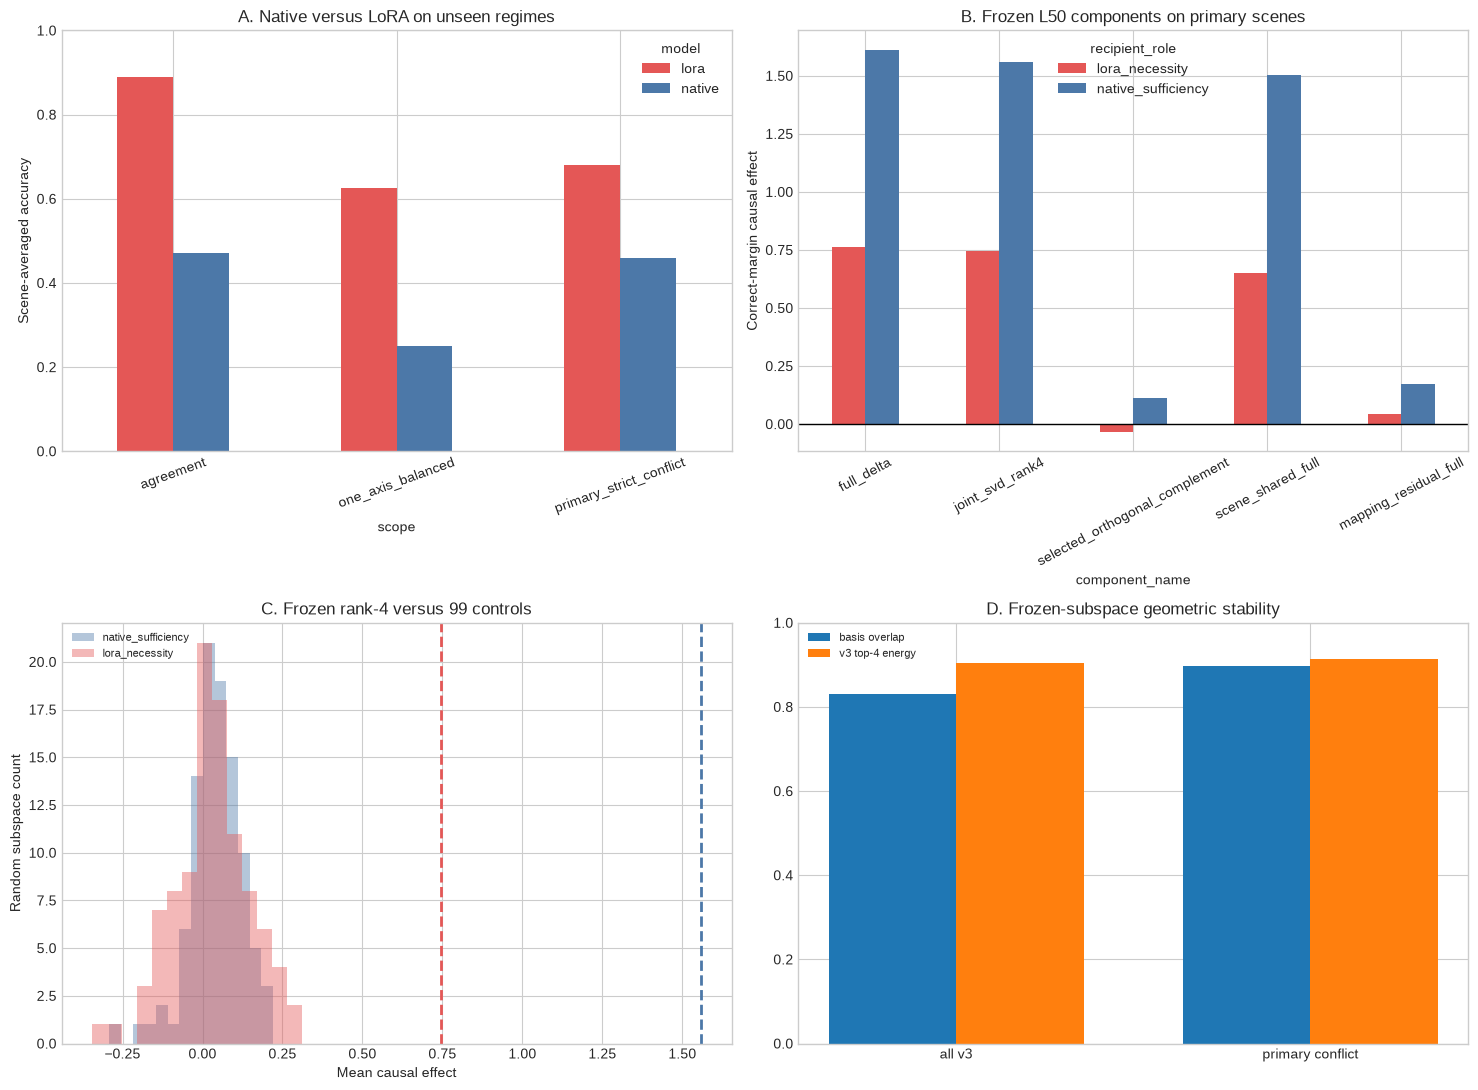

In [14]:
%%cell_progress 13/14 Test frozen rank-4 replication and mechanism boundaries
cell_stage('Loading causal patches and clean baselines')
patch_rows = []
for path in sorted(PATCH_DIR.glob('*.json')):
    if path.name == 'identity.json':
        continue
    patch_rows.extend(json.loads(path.read_text(encoding='utf-8'))['records'])
patch_frame = pd.DataFrame(patch_rows)
assert patch_frame['example_id'].nunique() == len(test_examples)

clean_wide = clean_frame.pivot(
    index='example_id', columns='model', values=['correct_margin', 'correct']
)
clean_wide.columns = ['_'.join(values) for values in clean_wide.columns]
clean_wide = clean_wide.reset_index()
prompt_effect = patch_frame.merge(
    clean_wide, on='example_id', validate='many_to_one'
)
prompt_effect['effect'] = np.where(
    prompt_effect['recipient_role'] == 'native_sufficiency',
    prompt_effect['correct_margin'] - prompt_effect['correct_margin_native'],
    prompt_effect['correct_margin_lora'] - prompt_effect['correct_margin'],
)
prompt_effect['accuracy_effect'] = np.where(
    prompt_effect['recipient_role'] == 'native_sufficiency',
    prompt_effect['correct'].astype(float) - prompt_effect['correct_native'].astype(float),
    prompt_effect['correct_lora'].astype(float) - prompt_effect['correct'].astype(float),
)
scene_effect = prompt_effect.groupby([
    'scene_id', 'regime', 'primary', 'weight_cue', 'outcome',
    'recipient_role', 'component_name', 'component_family', 'component_rank',
], as_index=False).agg(
    effect=('effect', 'mean'),
    accuracy_effect=('accuracy_effect', 'mean'),
    component_norm_fraction=('component_norm_fraction', 'mean'),
    component_energy_fraction=('component_energy_fraction', 'mean'),
)
scene_effect.to_csv(ANALYSIS_DIR / 'causal_scene_effects.csv', index=False)

primary_effect = scene_effect[scene_effect['primary']].copy()
full_by_role = {
    role: primary_effect[
        (primary_effect['recipient_role'] == role)
        & (primary_effect['component_name'] == 'full_delta')
    ].set_index('scene_id')['effect']
    for role in ('native_sufficiency', 'lora_necessity')
}
assert all(len(values) == 24 for values in full_by_role.values())

summary_rows = []
for component_index, (keys, group) in enumerate(primary_effect.groupby(
    ['component_name', 'recipient_role'], sort=True
)):
    component_name, role = keys
    current = group.set_index('scene_id')['effect']
    full = full_by_role[role].reindex(current.index)
    effect_summary = bootstrap_summary(
        current, SEED + 4000 + component_index
    )
    noninferiority = bootstrap_summary(
        current - NONINFERIORITY_FRACTION * full,
        SEED + 5000 + component_index,
    )
    summary_rows.append({
        'component_name': component_name,
        'recipient_role': role,
        'component_family': group['component_family'].iloc[0],
        'component_rank': int(group['component_rank'].iloc[0]),
        **{f'effect_{key}': value for key, value in effect_summary.items()},
        'accuracy_effect': float(group['accuracy_effect'].mean()),
        'mean_norm_fraction': float(group['component_norm_fraction'].mean()),
        'mean_energy_fraction': float(group['component_energy_fraction'].mean()),
        'recovery_of_full': float(
            current.mean() / max(abs(full.mean()), 1e-8)
        ),
        'noninferiority_mean': noninferiority['mean'],
        'noninferiority_ci_low': noninferiority['ci_low'],
        'noninferiority_ci_high': noninferiority['ci_high'],
    })
primary_summary = pd.DataFrame(summary_rows)
primary_summary.to_csv(ANALYSIS_DIR / 'primary_component_summary.csv', index=False)

cell_stage('Computing 99-control empirical specificity')
empirical = {}
for role in ('native_sufficiency', 'lora_necessity'):
    selected_rows = primary_effect[
        (primary_effect['recipient_role'] == role)
        & (primary_effect['component_name'] == SELECTED_NAME)
    ]
    selected_mean = float(selected_rows['effect'].mean())
    selected_efficiency = float(
        selected_mean / max(selected_rows['component_norm_fraction'].mean(), 1e-8)
    )
    random_rows = primary_effect[
        (primary_effect['recipient_role'] == role)
        & primary_effect['component_name'].str.startswith('random_subspace_')
    ]
    random_means = random_rows.groupby('component_name')['effect'].mean().sort_index()
    random_efficiency = random_rows.groupby('component_name').apply(
        lambda frame: frame['effect'].mean()
        / max(frame['component_norm_fraction'].mean(), 1e-8),
        include_groups=False,
    ).sort_index()
    assert len(random_means) == len(random_efficiency) == RANDOM_SUBSPACE_COUNT
    empirical[role] = {
        'selected_mean': selected_mean,
        'random_means': random_means.to_dict(),
        'raw_empirical_p': float(
            (1 + np.sum(random_means.to_numpy() >= selected_mean))
            / (RANDOM_SUBSPACE_COUNT + 1)
        ),
        'selected_effect_per_norm_fraction': selected_efficiency,
        'random_effect_per_norm_fraction': random_efficiency.to_dict(),
        'efficiency_empirical_p': float(
            (1 + np.sum(random_efficiency.to_numpy() >= selected_efficiency))
            / (RANDOM_SUBSPACE_COUNT + 1)
        ),
    }

cell_stage('Auditing answer-position and cross-regime generalization')
permutation_summaries = {}
for role_index, role in enumerate(('native_sufficiency', 'lora_necessity')):
    permutation_summaries[role] = {}
    selected_prompts = prompt_effect[
        prompt_effect['primary']
        & (prompt_effect['recipient_role'] == role)
        & (prompt_effect['component_name'] == SELECTED_NAME)
    ]
    for label_index, gold_label in enumerate(('A', 'B', 'C')):
        permutation_summaries[role][gold_label] = bootstrap_summary(
            selected_prompts.loc[
                selected_prompts['gold_label'] == gold_label, 'effect'
            ],
            SEED + 6000 + role_index * 100 + label_index,
        )

regime_rows = []
core_effect = scene_effect[
    scene_effect['component_name'].isin(CORE_COMPONENTS)
]
for group_index, (keys, group) in enumerate(core_effect.groupby(
    ['regime', 'component_name', 'recipient_role'], sort=True
)):
    regime, component_name, role = keys
    summary = bootstrap_summary(group['effect'], SEED + 7000 + group_index)
    regime_rows.append({
        'regime': regime,
        'component_name': component_name,
        'recipient_role': role,
        **{f'effect_{key}': value for key, value in summary.items()},
        'accuracy_effect': float(group['accuracy_effect'].mean()),
        'mean_norm_fraction': float(group['component_norm_fraction'].mean()),
    })
regime_summary = pd.DataFrame(regime_rows)
regime_summary.to_csv(ANALYSIS_DIR / 'cross_regime_component_summary.csv', index=False)

cell_stage('Measuring frozen-basis stability without refitting the intervention')
all_test_deltas = []
primary_test_deltas = []
for example in test_examples:
    payload = load_clean_payload(CLEAN_DIR, example)
    delta = payload['lora_state'].float() - payload['native_state'].float()
    all_test_deltas.append(delta.numpy())
    if selection_by_scene[example.scene_id]['primary']:
        primary_test_deltas.append(delta.numpy())

def diagnostic_top_basis(matrix, rank):
    _u, singular, vt = np.linalg.svd(
        np.asarray(matrix, dtype=np.float32), full_matrices=False
    )
    return vt[:rank].astype(np.float32), singular.astype(np.float32)

all_top4, all_singular = diagnostic_top_basis(all_test_deltas, SELECTED_RANK)
primary_top4, primary_singular = diagnostic_top_basis(
    primary_test_deltas, SELECTED_RANK
)

def subspace_stability(test_basis, singular):
    cosines = np.linalg.svd(
        selected_basis.numpy() @ test_basis.T,
        compute_uv=False,
    )
    return {
        'principal_angle_cosines': [float(value) for value in cosines],
        'mean_squared_cosine': float(np.mean(cosines ** 2)),
        'test_top4_energy_fraction': float(
            np.sum(singular[:SELECTED_RANK] ** 2)
            / np.sum(singular ** 2)
        ),
    }

stability = {
    'all_blind_v3': subspace_stability(all_top4, all_singular),
    'primary_strict_conflict': subspace_stability(
        primary_top4, primary_singular
    ),
    'note': (
        'These blind-v3 SVDs are post-hoc geometry diagnostics only. They are '
        'never used for intervention, selection, or the primary gate.'
    ),
}

def summary_row(component_name, role):
    row = primary_summary[
        (primary_summary['component_name'] == component_name)
        & (primary_summary['recipient_role'] == role)
    ]
    assert len(row) == 1
    return row.iloc[0]

selected_suff = summary_row(SELECTED_NAME, 'native_sufficiency')
selected_nec = summary_row(SELECTED_NAME, 'lora_necessity')
full_suff = summary_row('full_delta', 'native_sufficiency')
full_nec = summary_row('full_delta', 'lora_necessity')
primary_behavior_accuracy = paired_behavior[
    (paired_behavior['scope'] == 'primary_strict_conflict')
    & (paired_behavior['metric'] == 'accuracy_delta')
].iloc[0]
permutation_robust = all(
    permutation_summaries[role][label]['ci_low'] > 0
    for role in ('native_sufficiency', 'lora_necessity')
    for label in ('A', 'B', 'C')
)
gates = {
    'blind_v3_conflict_behavior_improves': bool(
        primary_behavior_accuracy['ci_low'] > 0
    ),
    'full_patch_sufficiency_replicates': bool(full_suff['effect_ci_low'] > 0),
    'full_patch_necessity_replicates': bool(full_nec['effect_ci_low'] > 0),
    'frozen_rank4_sufficient': bool(selected_suff['effect_ci_low'] > 0),
    'frozen_rank4_necessary': bool(selected_nec['effect_ci_low'] > 0),
    'frozen_rank4_sufficiency_at_least_80pct_full': bool(
        selected_suff['noninferiority_ci_low'] > 0
    ),
    'frozen_rank4_necessity_at_least_80pct_full': bool(
        selected_nec['noninferiority_ci_low'] > 0
    ),
    'frozen_rank4_beats_99_random_sufficiency': bool(
        empirical['native_sufficiency']['raw_empirical_p'] <= ALPHA_LEVEL
    ),
    'frozen_rank4_beats_99_random_necessity': bool(
        empirical['lora_necessity']['raw_empirical_p'] <= ALPHA_LEVEL
    ),
    'frozen_rank4_efficiency_beats_99_random_sufficiency': bool(
        empirical['native_sufficiency']['efficiency_empirical_p'] <= ALPHA_LEVEL
    ),
    'frozen_rank4_efficiency_beats_99_random_necessity': bool(
        empirical['lora_necessity']['efficiency_empirical_p'] <= ALPHA_LEVEL
    ),
    'frozen_rank4_permutation_robust': bool(permutation_robust),
}
gates['frozen_rank4_blindv3_confirmed'] = all(gates.values())

decision = {
    'schema_version': 'qwen27b-postlora-l50-frozen-rank4-blindv3-decision-1.0',
    'frozen_selection': selection_payload,
    'behavior_summary': behavior_summary.to_dict(orient='records'),
    'paired_behavior_summary': paired_behavior.to_dict(orient='records'),
    'primary_component_summary': primary_summary.to_dict(orient='records'),
    'cross_regime_component_summary': regime_summary.to_dict(orient='records'),
    'random_specificity': empirical,
    'permutation_summaries': permutation_summaries,
    'subspace_stability': stability,
    'gates': gates,
    'interpretation_limit': (
        'Passing supports a frozen low-dimensional causal state mediator for '
        'post-LoRA behavior on new strict-conflict scenes. It does not identify '
        'a unique circuit or demonstrate an explicit scalar multiplication algorithm.'
    ),
}
DECISION_PATH = ANALYSIS_DIR / 'blindv3_frozen_rank4_decision.json'
write_json_atomic(DECISION_PATH, decision)

key_names = [
    'full_delta', SELECTED_NAME, 'selected_orthogonal_complement',
    'scene_shared_full', 'mapping_residual_full',
]
display(primary_summary[
    primary_summary['component_name'].isin(key_names)
].sort_values(['recipient_role', 'component_name']).round(4))
print('Random empirical p:', {
    role: {
        'raw': values['raw_empirical_p'],
        'efficiency': values['efficiency_empirical_p'],
    } for role, values in empirical.items()
})
print('Frozen-basis stability:', stability)
print('Frozen gates:', gates)

cell_stage('Rendering one behavior-to-mechanism summary figure')
plt.style.use('seaborn-v0_8-whitegrid')
figure, axes = plt.subplots(2, 2, figsize=(15, 11))

behavior_plot = behavior_summary[
    behavior_summary['scope'].isin([
        'primary_strict_conflict', 'agreement', 'one_axis_balanced'
    ])
].pivot(index='scope', columns='model', values='accuracy')
behavior_plot.plot(kind='bar', ax=axes[0, 0], color=['#E45756', '#4C78A8'])
axes[0, 0].set_ylim(0, 1)
axes[0, 0].set_ylabel('Scene-averaged accuracy')
axes[0, 0].set_title('A. Native versus LoRA on unseen regimes')
axes[0, 0].tick_params(axis='x', rotation=20)

effect_plot = primary_summary[
    primary_summary['component_name'].isin(key_names)
].pivot(index='component_name', columns='recipient_role', values='effect_mean')
effect_plot = effect_plot.reindex([name for name in key_names if name in effect_plot.index])
effect_plot.plot(kind='bar', ax=axes[0, 1], color=['#E45756', '#4C78A8'])
axes[0, 1].axhline(0, color='black', linewidth=1)
axes[0, 1].set_ylabel('Correct-margin causal effect')
axes[0, 1].set_title('B. Frozen L50 components on primary scenes')
axes[0, 1].tick_params(axis='x', rotation=28)

for role, color in (
    ('native_sufficiency', '#4C78A8'),
    ('lora_necessity', '#E45756'),
):
    random_values = np.asarray(list(empirical[role]['random_means'].values()))
    axes[1, 0].hist(random_values, bins=14, alpha=0.42, color=color, label=role)
    axes[1, 0].axvline(
        empirical[role]['selected_mean'], color=color,
        linewidth=2, linestyle='--',
    )
axes[1, 0].set_xlabel('Mean causal effect')
axes[1, 0].set_ylabel('Random subspace count')
axes[1, 0].set_title('C. Frozen rank-4 versus 99 controls')
axes[1, 0].legend(fontsize=8)

stability_labels = ['all v3', 'primary conflict']
stability_values = [
    stability['all_blind_v3']['mean_squared_cosine'],
    stability['primary_strict_conflict']['mean_squared_cosine'],
]
energy_values = [
    stability['all_blind_v3']['test_top4_energy_fraction'],
    stability['primary_strict_conflict']['test_top4_energy_fraction'],
]
x = np.arange(len(stability_labels))
axes[1, 1].bar(x - 0.18, stability_values, 0.36, label='basis overlap')
axes[1, 1].bar(x + 0.18, energy_values, 0.36, label='v3 top-4 energy')
axes[1, 1].set_xticks(x, stability_labels)
axes[1, 1].set_ylim(0, 1)
axes[1, 1].set_title('D. Frozen-subspace geometric stability')
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
SUMMARY_FIGURE_PATH = FIGURE_DIR / 'blindv3_frozen_rank4_summary.png'
plt.savefig(SUMMARY_FIGURE_PATH, dpi=180, bbox_inches='tight')
plt.show()


In [15]:
%%cell_progress 14/14 Verify the complete blind-v3 replication package
cell_stage('Checking files, counts, and immutable ordering')
required_outputs = (
    PROTOCOL_LOCK_PATH, DATASET_LOCK_PATH, MANIFEST_LOCK_PATH,
    OUTPUT_ROOT / 'blind_v3_scene_manifest.jsonl', TEST_MANIFEST_PATH,
    CLEAN_DIR / 'identity.json', CLEAN_DIR / 'index.jsonl',
    CLEAN_DIR / 'self_patch_parity.json',
    RANDOM_SUBSPACE_PATH, CONTROL_LOCK_PATH, PATCH_IDENTITY_PATH,
    ANALYSIS_DIR / 'clean_prompt_predictions.jsonl',
    ANALYSIS_DIR / 'clean_scene_behavior.csv',
    ANALYSIS_DIR / 'behavior_summary.csv',
    ANALYSIS_DIR / 'paired_behavior_changes.csv',
    ANALYSIS_DIR / 'paired_behavior_summary.csv',
    ANALYSIS_DIR / 'causal_scene_effects.csv',
    ANALYSIS_DIR / 'primary_component_summary.csv',
    ANALYSIS_DIR / 'cross_regime_component_summary.csv',
    DECISION_PATH, SUMMARY_FIGURE_PATH,
)
missing = [str(path) for path in required_outputs if not Path(path).is_file()]
assert not missing, 'Missing required outputs:\n' + '\n'.join(missing)
assert len(list(CLEAN_DIR.glob('*.pt'))) == len(test_examples)
assert len([
    path for path in PATCH_DIR.glob('*.json') if path.name != 'identity.json'
]) == len(test_examples)

completion = {
    'schema_version': 'qwen27b-postlora-l50-frozen-rank4-blindv3-complete-1.0',
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'adapter_dir': str(ADAPTER_DIR),
    'fresh_blind_v3_scenes': len(selection_rows),
    'primary_scenes': sum(row['primary'] for row in selection_rows),
    'secondary_audit_scenes': sum(not row['primary'] for row in selection_rows),
    'permutations_per_scene': 3,
    'frozen_subspace': selected,
    'random_subspace_count': RANDOM_SUBSPACE_COUNT,
    'decision_path': str(DECISION_PATH),
    'summary_figure_path': str(SUMMARY_FIGURE_PATH),
    'required_outputs': [str(path) for path in required_outputs],
}
RUN_COMPLETE_PATH = OUTPUT_ROOT / 'RUN_COMPLETE.json'
write_json_atomic(RUN_COMPLETE_PATH, completion)
print('Blind-v3 frozen-rank4 replication complete:', RUN_COMPLETE_PATH)
print('Primary decision:', DECISION_PATH)
print('Summary figure:', SUMMARY_FIGURE_PATH)


Verify the complete blind-v3 replication package:  93%|#########2| 13/14 [00:00<?, ?cell/s]

Blind-v3 frozen-rank4 replication complete: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_frozen_rank4_blindv3_v1/RUN_COMPLETE.json
Primary decision: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_frozen_rank4_blindv3_v1/analysis/blindv3_frozen_rank4_decision.json
Summary figure: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_frozen_rank4_blindv3_v1/analysis/figures/blindv3_frozen_rank4_summary.png
